# 01 · Data Pipeline: sensors.AFRICA raw archive → hourly Nairobi dataset

**Project:** An Explainable, Ensemble-Based ML System for Detecting Anomalous Air Pollution Events in Nairobi's Low-Cost Sensor Network
**Author:** Baya Isaac (222327) · DSA 8401 Applied Machine Learning · Strathmore University

This notebook rebuilds `NAIROBI_HOURLY_AIRQUALITY_DATASET_merged.xlsx` from the raw sensors.AFRICA archive. Every step calls the same functions as the scripted pipeline (`python -m airq.pipeline ingest`), so the notebook and the script cannot drift apart.

| Step | What happens | Code |
|---|---|---|
| 1 | Get the monthly raw CSVs (download from openAFRICA, or use files already on disk) | `ingest.download_archive`, `ingest.find_raw_files` |
| 2 | Inspect one raw file | `pandas` |
| 3 | Tidy each file: keep 5 value types, float32 values, drop exact duplicates, floor to the hour | `ingest.read_raw_file` |
| 4 | Aggregate to hourly means per location with running sums/counts; record the sensor types that reported | `ingest.HourlyAccumulator` |
| 5 | Location coordinates and reverse-geocoded neighbourhood names (frozen cache + Nominatim) | `ingest.location_coordinates`, `geocode.geocode_locations` |
| 6 | Calendar columns (UTC, as in the archive) | `ingest.add_calendar` |
| 7 | Assemble in the published column order and save (`.xlsx` + `.csv.gz`) | `ingest.build_dataset`, `ingest.save_dataset` |
| 8 | Quality report (impossible values are **kept** here; cleaning happens in notebook 02) | `validate.schema_report` |
| 9 | Validate against the published file | `validate.compare` |

### Raw format
The archive is published on openAFRICA as one `;`-separated CSV per month in long format:

```
sensor_id;sensor_type;location;lat;lon;timestamp;value_type;value
2582;pms5003;3573;-1.270;36.810;2023-01-01T00:00:43.437733+00:00;P2;19.00
```

| `value_type` | Dataset column | Meaning |
|---|---|---|
| `P0` | `PM1` | PM1 (µg/m³) |
| `P2` | `PM25` | PM2.5 (µg/m³) |
| `P1` | `PM10` | PM10 (µg/m³) |
| `humidity` | `HUMIDITY` | relative humidity (%) |
| `temperature` | `TEMPERATURE` | °C |

A **location** is a site; several physical sensors (e.g. a `DHT22` for humidity and an `SDS011` for PM) share one location. The hourly dataset is therefore keyed by `(LOCATION, hour)`, and `SENSOR_TYPE` lists the sensor types that reported at that site in that hour.

> **Design choice: no cleaning here.** The published dataset is deliberately *semi-raw* (the course requires real-world messiness): impossible humidity values, the `65535` firmware sentinel and PM values above the sensors' measuring range are all left in. Notebook 02 cleans them with documented, training-only rules.

## 0. Setup

In [1]:
import os, sys, logging
from pathlib import Path

# Make the repository's src/ importable whether this runs from notebooks/ or the repo root
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
os.environ.setdefault('AIRQ_ROOT', str(ROOT))
sys.path.insert(0, str(ROOT / 'src'))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from airq.config import load_config, resolve
from airq.data import ingest, geocode, validate

logging.basicConfig(level=logging.INFO, format='%(levelname)s %(name)s: %(message)s')
pd.set_option('display.max_columns', None)
cfg = load_config()
print('Repository root:', ROOT)
print('Archive window :', cfg['ingest']['start_month'], '->', cfg['ingest']['end_month'])

Repository root: /home/claude/repo
Archive window : 2019-01 -> 2026-06


## 1. Get the raw monthly files

| Option | When | How |
|---|---|---|
| **A. Download** | Internet access to `open.africa` | set `DOWNLOAD = True`; files land in `data/raw/` (already-downloaded months are skipped) |
| **B. Local files** | You already have the monthly CSVs | copy them into `data/raw/` (any file name; `.csv` or `.csv.gz`) |
| **C. Offline sample** | No raw data available | the notebook falls back to `data/sample_raw/`: archive-format files for 2019-01 and 2025-11 generated by `scripts/make_sample_raw.py` from the published dataset, so every step can still be run and checked |

The full archive (Jan 2019 – Jun 2026) is several GB of raw readings; files are processed one at a time, so memory stays bounded.

In [2]:
DOWNLOAD = False          # set True to fetch the archive from openAFRICA (needs internet)
RAW_DIR = cfg['ingest']['raw_dir']

if DOWNLOAD:
    ingest.download_archive(cfg, RAW_DIR)

raw_files = ingest.find_raw_files(RAW_DIR)
if not raw_files:
    RAW_DIR = 'data/sample_raw'
    raw_files = ingest.find_raw_files(RAW_DIR)
    print('data/raw/ is empty -> using the offline sample in data/sample_raw/')
USING_SAMPLE = RAW_DIR == 'data/sample_raw'
print(f'{len(raw_files)} raw file(s):')
for p in raw_files:
    print(f'  {p.name:45s} {p.stat().st_size/1e6:8.2f} MB')

data/raw/ is empty -> using the offline sample in data/sample_raw/
2 raw file(s):
  sensorsafrica_nairobi_2019-01.csv.gz              0.69 MB
  sensorsafrica_nairobi_2025-11.csv.gz              0.06 MB


## 2. Inspect one raw file

In [3]:
first = raw_files[0]
sep = ingest._sniff_sep(first)
peek = pd.read_csv(first, sep=sep, dtype=str, nrows=200_000)
print(f'{first.name}: separator {sep!r}, columns {list(peek.columns)}')
display(peek.head())
print('\nvalue_type counts:'); print(peek['value_type'].value_counts().to_string())
print('\nsensor_type counts:'); print(peek['sensor_type'].value_counts().to_string())
print('\nExample timestamps (note the +00:00 = UTC):', peek['timestamp'].head(3).tolist())

sensorsafrica_nairobi_2019-01.csv.gz: separator ';', columns ['sensor_id', 'sensor_type', 'location', 'lat', 'lon', 'timestamp', 'value_type', 'value']


,sensor_id,sensor_type,location,lat,lon,timestamp,value_type,value
0,210,DHT22,21,-1.287,36.811,2019-01-01T00:30:00.000000+00:00,humidity,79.620834
1,210,DHT22,21,-1.287,36.811,2019-01-01T00:35:00.000000+00:00,humidity,81.620834
2,210,DHT22,21,-1.287,36.811,2019-01-01T00:45:00.000000+00:00,humidity,83.620834
3,210,DHT22,21,-1.287,36.811,2019-01-01T00:00:00.000000+00:00,temperature,13.083333
4,210,DHT22,21,-1.287,36.811,2019-01-01T00:02:30.000000+00:00,temperature,15.083333



value_type counts:
value_type
P2             25743
P1             25743
humidity       21795
temperature    21795

sensor_type counts:
sensor_type
SDS011    51486
DHT22     43590

Example timestamps (note the +00:00 = UTC): ['2019-01-01T00:30:00.000000+00:00', '2019-01-01T00:35:00.000000+00:00', '2019-01-01T00:45:00.000000+00:00']


## 3. Tidy each file

`read_raw_file` yields chunks with one row per raw reading:

* keeps only the five value types above (other channels, e.g. noise, are ignored),
* drops exact duplicate rows (same sensor, timestamp, value type and value: double uploads),
* parses timestamps as UTC and floors them to the hour,
* stores values as **float32**. The sensors report single-precision numbers, and float32 is what reproduces the published values exactly (e.g. `99.900002`, `36.811001` in the published file are float32 artefacts).

In [4]:
tidy = next(iter(ingest.read_raw_file(first, cfg)))
print(tidy.dtypes)
tidy.head()

LOCATION                int64
SENSOR_ID                 str
SENSOR_TYPE               str
LAT                   float32
LON                   float32
HOUR_UTC       datetime64[us]
VARIABLE                  str
VALUE                 float32
dtype: object


,LOCATION,SENSOR_ID,SENSOR_TYPE,LAT,LON,HOUR_UTC,VARIABLE,VALUE
0,21,210,DHT22,-1.287,36.811001,2019-01-01,HUMIDITY,79.620834
1,21,210,DHT22,-1.287,36.811001,2019-01-01,HUMIDITY,81.620834
2,21,210,DHT22,-1.287,36.811001,2019-01-01,HUMIDITY,83.620834
3,21,210,DHT22,-1.287,36.811001,2019-01-01,TEMPERATURE,13.083333
4,21,210,DHT22,-1.287,36.811001,2019-01-01,TEMPERATURE,15.083333


## 4. Hourly aggregation

For every `(LOCATION, hour, variable)` the accumulator keeps a running **sum and count**, so files are processed one at a time and an hour whose readings sit in two files is still averaged correctly. The hourly value is `sum / count` (the mean of all raw readings in that hour, across all sensors of that type at the site). It also records which sensor types reported at the site in that hour; `SENSOR_TYPE` is their sorted, comma-joined list (e.g. `DHT22, SDS011`). Hours in which none of the five variables was reported are dropped.

In [5]:
acc = ingest.HourlyAccumulator()
for path in raw_files:
    for chunk in ingest.read_raw_file(path, cfg):
        acc.add(chunk)
hourly, coords = acc.result()
print(f'Hourly rows: {len(hourly):,} | locations: {hourly["LOCATION"].nunique()}')
hourly.head()

Hourly rows: 9,626 | locations: 24


,LOCATION,HOUR_UTC,PM1,PM25,PM10,HUMIDITY,TEMPERATURE,SENSOR_TYPE
0,6,2019-01-18 17:00:00,NaN,6.850000,11.935000,62.366669,23.400000,"DHT22, SDS011"
1,6,2019-01-18 18:00:00,NaN,7.066875,12.638124,62.126666,23.466667,"DHT22, SDS011"
2,6,2019-01-18 19:00:00,NaN,8.192105,15.062105,62.405884,23.588236,"DHT22, SDS011"
3,6,2019-01-18 20:00:00,NaN,6.839445,11.853333,61.866665,23.600000,"DHT22, SDS011"
4,6,2019-01-18 21:00:00,NaN,6.182222,10.157223,61.841179,23.552940,"DHT22, SDS011"


## 5. Coordinates and neighbourhood names

**Coordinates.** Each location's latitude and longitude are its most frequent values in the archive (the archive rounds them to 3 decimals, about 110 m). They are taken separately, so a site that never reported a latitude keeps its longitude and gets `NaN` latitude, exactly as in the published file (location 4014).

> The columns are called `NEIGHBORHOOD_LAT/LON` in the published file, but they hold the **sensor site's** coordinates; sensors in the same neighbourhood have different coordinates.

**Neighbourhood names** come from reverse geocoding with OpenStreetMap Nominatim (first available of `suburb`, `neighbourhood`, `quarter`, `city_district`, … in the address). Nominatim's answers change as OSM is edited, so the names used in the published dataset are frozen in `data/reference/sensor_locations.csv`. A location is only re-queried if it is new or its coordinates moved; with `allow_network=False` new locations become `Unknown` instead. Sites without coordinates are labelled `No coordinates`.

In [6]:
cache = geocode.load_cache()
print(f'Geocode cache: {len(cache)} locations, {cache["NEIGHBORHOOD"].nunique()} neighbourhood names')
names = geocode.geocode_locations(coords, cfg, allow_network=not USING_SAMPLE)
names

Geocode cache: 53 locations, 27 neighbourhood names


,LOCATION,LAT,LON,NEIGHBORHOOD
0,6,-1.259,36.799000,Parklands/Highridge ward
1,7,-1.298,36.791000,Kilimani sublocation
2,18,-1.292,36.820999,CBD division
3,21,-1.287,36.811001,Kilimani sublocation
4,25,-1.301,36.754002,Kawangware division
5,27,-1.306,36.772999,Woodley/Kenyatta/Golf Course ward
6,28,-1.291,36.724998,Waithaka division
7,29,-1.300,36.785000,Woodley/Kenyatta/Golf Course ward
8,30,-1.290,36.777000,Kileleshwa sublocation
9,31,-1.291,36.780998,Kilimani sublocation


## 6. Calendar columns (UTC)

`DATE`, `TIME`, `YEAR`, `MONTH`, `WEEKDAY` and `HOUR` are derived from the **UTC** hour, as in the archive and the published file. The check below confirms the timestamps are UTC: Nairobi's traffic peaks (about 07:00 and 19:00–20:00 local, EAT = UTC+3) appear at about 04:00 and 16:00–17:00 in the file. Notebook 02 converts to local time before modelling, because rush hours and weekdays are local phenomena.

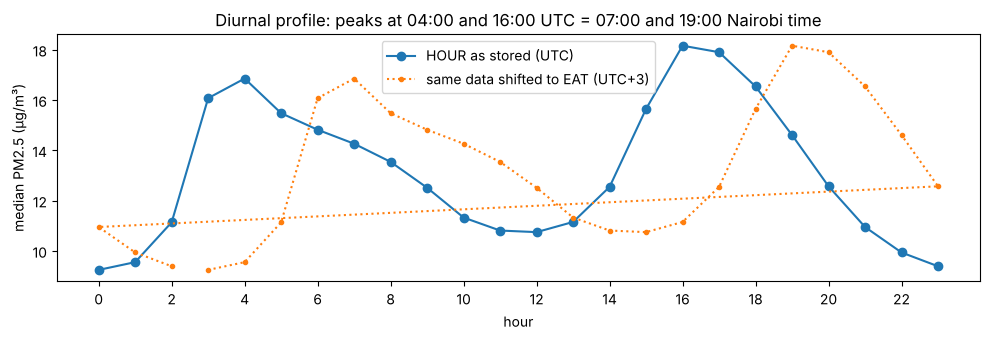

Top-4 hours (UTC): [16, 17, 4, 18]


In [7]:
ref_path = resolve(cfg['data_path'])
probe = ingest.load_dataset(ref_path) if ref_path.exists() else hourly.assign(HOUR=hourly['HOUR_UTC'].dt.hour)
prof = probe.groupby('HOUR')['PM25'].median()
fig, ax = plt.subplots(figsize=(10, 3.5))
ax.plot(prof.index, prof.values, marker='o', label='HOUR as stored (UTC)')
ax.plot((prof.index + 3) % 24, prof.values, marker='.', ls=':', label='same data shifted to EAT (UTC+3)')
ax.set_xticks(range(0, 24, 2)); ax.set_xlabel('hour'); ax.set_ylabel('median PM2.5 (µg/m³)')
ax.set_title('Diurnal profile: peaks at 04:00 and 16:00 UTC = 07:00 and 19:00 Nairobi time'); ax.legend()
plt.tight_layout(); plt.show()
print('Top-4 hours (UTC):', prof.sort_values(ascending=False).head(4).index.tolist())

## 7. Assemble and save

In [8]:
dataset = ingest.build_dataset(raw_files, cfg, allow_network_geocoding=not USING_SAMPLE)
assert list(dataset.columns) == ingest.OUTPUT_COLUMNS
display(dataset.head())

if USING_SAMPLE:
    # Never overwrite the published dataset with the 2-month sample
    out = resolve('data/processed/sample_rebuild.csv.gz')
    dataset.to_csv(out, index=False, compression='gzip')
    print('Sample rebuild written to', out)
else:
    paths = ingest.save_dataset(dataset, cfg, xlsx=True)
    print('Saved:', paths)

INFO airq.data.ingest: Read sensorsafrica_nairobi_2019-01.csv.gz


INFO airq.data.ingest: Read sensorsafrica_nairobi_2025-11.csv.gz


INFO airq.data.ingest: Processed 2 raw files


,DATE,TIME,PM1,PM25,PM10,HUMIDITY,TEMPERATURE,LOCATION,NEIGHBORHOOD,SENSOR_TYPE,YEAR,MONTH,WEEKDAY,HOUR,NEIGHBORHOOD_LAT,NEIGHBORHOOD_LON
0,2019-01-01,00:00:00,NaN,6.228333,9.785833,81.620834,15.083333,21,Kilimani sublocation,"DHT22, SDS011",2019,1,Tuesday,0,-1.287,36.811001
1,2019-01-01,00:00:00,NaN,8.235416,8.887083,99.900002,16.933332,27,Woodley/Kenyatta/Golf Course ward,"DHT22, SDS011",2019,1,Tuesday,0,-1.306,36.772999
2,2019-01-01,00:00:00,NaN,12.682800,24.133600,90.444000,17.275999,29,Woodley/Kenyatta/Golf Course ward,"DHT22, SDS011",2019,1,Tuesday,0,-1.300,36.785000
3,2019-01-01,00:00:00,NaN,18.980434,33.828697,89.327271,17.009092,30,Kileleshwa sublocation,"DHT22, SDS011",2019,1,Tuesday,0,-1.290,36.777000
4,2019-01-01,00:00:00,NaN,16.564348,26.259130,64.434784,20.900000,31,Kilimani sublocation,"DHT22, SDS011",2019,1,Tuesday,0,-1.291,36.780998


Sample rebuild written to /home/claude/repo/data/processed/sample_rebuild.csv.gz


## 8. Quality report

These counts describe the *raw* hourly data. They motivate the cleaning rules in notebook 02 (Section 5).

In [9]:
print(validate.schema_report(dataset))
q = pd.Series({
    'rows': len(dataset),
    'locations': dataset['LOCATION'].nunique(),
    'neighbourhoods': dataset['NEIGHBORHOOD'].nunique(),
    'PM2.5 missing (%)': 100 * dataset['PM25'].isna().mean(),
    'humidity missing (%)': 100 * dataset['HUMIDITY'].isna().mean(),
    'humidity outside 0-100 %': ((dataset['HUMIDITY'] < 0) | (dataset['HUMIDITY'] > 100)).sum(),
    'firmware sentinel 65535': (dataset[['HUMIDITY', 'TEMPERATURE']] == 65535).any(axis=1).sum(),
    'PM above sensor range (>1000)': ((dataset['PM25'] > 1000) | (dataset['PM10'] > 1000)).sum(),
    'rows with no coordinates': (dataset['NEIGHBORHOOD'] == 'No coordinates').sum(),
})
print(q.round(2).to_string())
print('\nRows per year:'); print(dataset['YEAR'].value_counts().sort_index().to_string())
print('\nSensor-type combinations:'); print(dataset['SENSOR_TYPE'].value_counts().to_string())

{'columns_match': True, 'missing_columns': [], 'rows': 9626, 'duplicate_keys': 0, 'all_measures_missing_rows': 0}
rows                             9626.00
locations                          24.00
neighbourhoods                     16.00
PM2.5 missing (%)                   4.00
humidity missing (%)               17.66
humidity outside 0-100 %            0.00
firmware sentinel 65535             0.00
PM above sensor range (>1000)       0.00
rows with no coordinates           26.00

Rows per year:
YEAR
2019    8965
2025     661

Sensor-type combinations:
SENSOR_TYPE
DHT22, SDS011     6881
SDS011            1700
DHT22, pms5003     660
DHT22              385


## 9. Validate against the published dataset

The rebuilt rows are matched with the published file on `(DATE, TIME, LOCATION)`. With the full archive every row should match; with the offline sample only the sample months are compared. Numeric columns are compared with a tolerance of 1e-4 (relative), because hourly means of float32 readings can differ in the last binary digit depending on summation order.

In [10]:
if ref_path.exists():
    ref = ingest.load_dataset(ref_path)
    months = set(dataset['DATE'].dt.strftime('%Y-%m'))
    ref_cmp = ref[ref['DATE'].dt.strftime('%Y-%m').isin(months)] if USING_SAMPLE else ref
    rep = validate.compare(dataset, ref_cmp)
    validate.print_report(rep)
    assert rep['only_in_rebuilt'] == 0 and rep['only_in_reference'] == 0, 'Row sets differ'
    assert all(v.get('nan_mismatches', 0) == 0 for v in rep['columns'].values()), 'Missingness differs'
    print('\nValidation passed: the pipeline reproduces the published rows' + (' for the sample months.' if USING_SAMPLE else '.'))
else:
    print('Published dataset not found; skipping comparison.')

rows rebuilt=9,626  reference=9,626  matched=9,626  only-new=0  only-ref=0
  PM1                nan_mismatches=0  share_equal=1  max_abs_diff=3.17891e-07
  PM25               nan_mismatches=0  share_equal=1  max_abs_diff=1.27157e-06
  PM10               nan_mismatches=0  share_equal=1  max_abs_diff=2.54313e-06
  HUMIDITY           nan_mismatches=0  share_equal=1  max_abs_diff=1.27157e-06
  TEMPERATURE        nan_mismatches=0  share_equal=1  max_abs_diff=9.53674e-07
  NEIGHBORHOOD_LAT   nan_mismatches=0  share_equal=1  max_abs_diff=4.44089e-16
  NEIGHBORHOOD_LON   nan_mismatches=0  share_equal=1  max_abs_diff=7.10543e-15
  NEIGHBORHOOD       share_equal=1
  SENSOR_TYPE        share_equal=1
  WEEKDAY            share_equal=1
  HOUR               share_equal=1
  YEAR               share_equal=1
  MONTH              share_equal=1

Validation passed: the pipeline reproduces the published rows for the sample months.


## Summary

* The pipeline is scripted (`src/airq/data/`) and runnable from the command line:
  `python -m airq.pipeline ingest --download` (or `--raw-dir <folder>`).
* Output schema, row set, row order, sensor-type strings, neighbourhood names and values match the published file.
* Known limitations: (1) the original notebook's exact Nominatim address-key order is not recorded, so the frozen cache, not a fresh query, guarantees the published names; (2) exact duplicate raw rows are dropped, which the original pipeline may not have done; (3) the full-archive comparison needs the raw files (several GB), so the repository ships an offline sample and a round-trip test (`tests/test_ingest.py`).